# Quick start

In lumped-element experiments, a static magnetic field lets axion dark matter drive oscillating flux through a pickup circuit.
In this tutorial we build a toroidal axion detector, compute its signal coupling and pickup inductance,
and inspect the fields. The [installation guide](../docs/guides/install.md) covers setup; the cells below should be run in order.

## Geometry and field solve

`templates` lists the available designs. `template` creates a toroid with dimensions
in metres; `set` changes a parameter. `solve` computes the static magnet and pickup
fields and writes the results to a run directory.

The summary reports coupling, inductance, stored energy, and field peaks.

We import axionFEM and display its version and available designs to check the setup.

In [1]:
import tempfile
from pathlib import Path

import axionfem as af
from IPython.display import Image, display

print("axionFEM", af.__version__)
RUNS = Path(tempfile.mkdtemp(prefix="axf_quickstart_"))     # solver run directories
[t["name"] for t in af.templates()]

axionFEM 0.1.0


['toroid', 'solenoid', 'core']

We create a toroid and set its `y` parameter to define the detector geometry.

In [2]:
d = af.template("toroid", R=2.0, H=2.0)
d.set(y=0.6)
d

Design('toroid'; H=2.0, NI=1000000.0, R=2.0, f=0.02*R, g=0.005*R, ts=0.005*R, tw=0.01*R, y=0.6)

We solve for the static magnet and pickup fields and print the summary to obtain the signal coupling and pickup inductance.

In [3]:
res = d.solve(RUNS / "toroid", verbose=0)
print(res.summary().split("\n  benchmark ")[0])    # the figures of merit (per-benchmark lines follow in the full summary)
b = res.benchmark("optimistic")                     # an illustrative readout benchmark
print(f"  optimistic benchmark: F/F_req = {b['F_over_F_req']:.3e}, field amplitude x{b['amplitude_scale']:.2f} to meet it")

design 'toroid'
  Psi      = 3.088e-07 H T m^2  (0.2458 T m^3 natural)
  L_p      = 1.458e-06 H
  W_mag    = 1.046e+05 J
  F        = 4.276e-15 T^4 H^2 m^8
  g        = 0.09511
  |B|max   = 0.1667 T  at r = 1.200 m, z = 0.437 m (winding)
  SC surface peak [sheath] = 2.407e-18 T
  optimistic benchmark: F/F_req = 2.594e-07, field amplitude x44.31 to meet it


## Field inspection

`show` opens the interactive viewer. `quantities` lists fields; `quantity` selects one and `scale` sets its color scale.
`pickup_Bmag` is the magnetic field per ampere of pickup current. The executed copy of this notebook does not store the
viewer widgets; static images of the same views follow the interactive cells.

We open the viewer to inspect the computed fields.

In [4]:
w = res.show(height=520)
w

We list the available field quantities to choose a view.

In [5]:
w.quantities

['Bmag', 'Br', 'Bz', 'Bphi', 'psi', 'pickup_Bmag', 'pickup_psi']

We display `pickup_Bmag` on a logarithmic scale to inspect the pickup field.

In [6]:
# The field of a unit readout current, on a log scale.
w.quantity = "pickup_Bmag"
w.scale = "log"
w.quantity

'pickup_Bmag'

We display `Bphi` in a meridional section to show its spatial distribution.

In [7]:
# The meridional section, as a second widget.
res.show(mode="section", quantity="Bphi", height=420)

The static images below are rendered by `res.png`, which also works without a browser: the static field, the pickup field on a logarithmic scale, and the `Bphi` section.

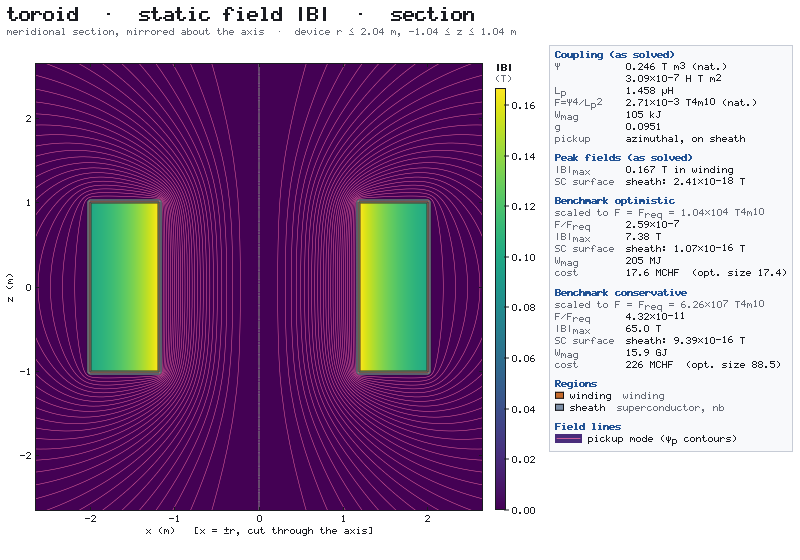

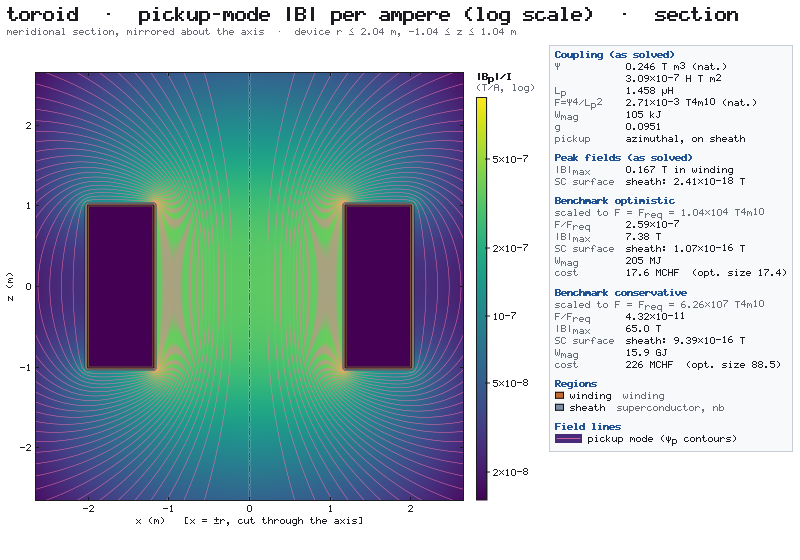

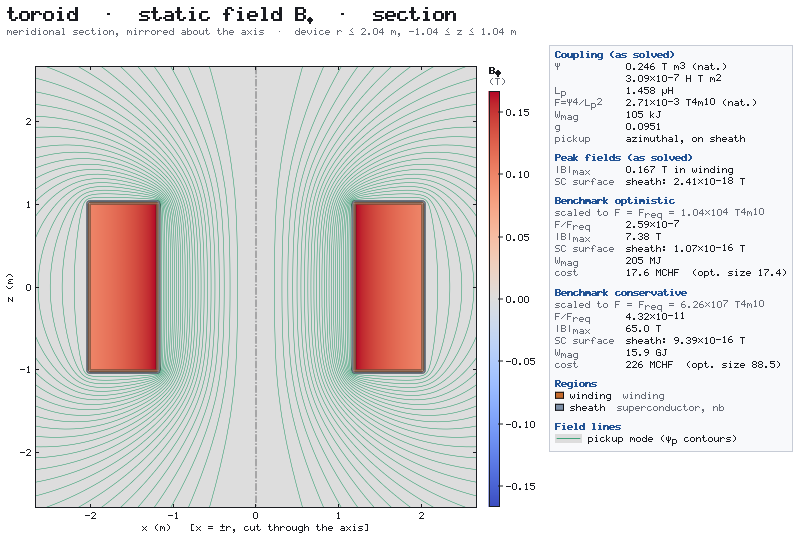

In [8]:
for name, kw in (("bmag", dict(quantity="Bmag")), ("pickup", dict(quantity="pickup_Bmag", log_scale=True)),
                 ("bphi", dict(quantity="Bphi"))):
    display(Image(filename=str(res.png(RUNS / f"{name}.png", view="section", width=800, height=560, **kw)), width=420))

## Results and exports

`Psi` is the signal coupling in H T m², `L_p` the pickup inductance in H, and `F`
the scan figure of merit. $\mathcal F/\mathcal F_{\rm req}\geq1$ meets the selected scan target;
the `optimistic` preset, an illustrative benchmark, assumes noise below the standard quantum limit. The
benchmark also reports the stored energy and peak field the design needs to reach the requirement.

`sample` evaluates fields at cylindrical coordinates in metres. HTML and PNG
exports save views. Mesh convergence should be checked before using numerical values for
design decisions.

We report `Psi`, `L_p`, `F`, and the `optimistic` benchmark ratio, energy and peak field at the requirement.

In [9]:
print(f"Psi = {res.Psi:.4g} H T m^2   L_p = {res.L_p:.4g} H   F = {res.F:.4g}")
b = res.benchmark("optimistic")
print(f"F/F_req = {b['F_over_F_req']:.4g}   at the requirement: W = {b['W_mag_at_req_J']:.4g} J, "
      f"B_max = {b['B_max_at_req_T']:.4g} T")

Psi = 3.088e-07 H T m^2   L_p = 1.458e-06 H   F = 4.276e-15
F/F_req = 2.594e-07   at the requirement: W = 2.054e+08 J, B_max = 7.385 T


We sample the field at three midplane points to compare values at different radii.

In [10]:
res.sample([0.5, 1.5, 2.5], [0.0, 0.0, 0.0])  # B at three points on the midplane

{'Br': array([0., 0., 0.]),
 'Bz': array([0., 0., 0.]),
 'Bphi': array([0.        , 0.13333333, 0.        ]),
 'psi': array([0., 0., 0.]),
 'pickup_Br': array([ 2.10286921e-12,  0.00000000e+00, -1.83508211e-12]),
 'pickup_Bz': array([ 3.40266518e-07,  0.00000000e+00, -2.29303163e-08]),
 'pickup_Bphi': array([0., 0., 0.]),
 'pickup_psi': array([4.22068356e-08, 2.32124557e-07, 2.06152264e-07]),
 'region_attr': array([1., 1., 1.])}

We export a standalone HTML page and a PNG section view to share the field results.

In [11]:
page = res.export_html(RUNS / "toroid.html")
png = res.png(RUNS / "toroid.png", view="section", quantity="Bphi")
print(page.name, png.name)

toroid.html toroid.png


## Full 3D

`axionfem.convert.to_3d` revolves an axisymmetric design into a 3D model, which the 3D engine of the MPI build solves;
3D models also describe ports, slits and fields without axial symmetry. `af.build_info()["engine_3d"]` reports
whether the installed build has the engine (the [installation guide](../docs/guides/install.md) describes the builds).

The next cell revolves a smaller toroid, whose 4 to 6 cm layers a coarse first-order 3D mesh resolves (the 1 to 2 cm
layers of the toroid above need a finer surface mesh), solves it in 3D in this Python process and compares the result
with the axisymmetric solve of the same design. `solve(..., mpi_ranks=4)` runs the 3D solve on 4 MPI ranks instead
([3D designs, MPI and clusters](../docs/guides/3d.md)).

In [12]:
if af.build_info()["engine_3d"]:
    from axionfem.convert import to_3d

    d_small = af.template("toroid", R=1.0, H=1.0, tw=0.06, g=0.04, ts=0.05, f=0.06)
    d3 = to_3d(d_small, mesh={"size": 0.45, "surface_size": 0.18, "order": 1})   # coarse, first-order elements
    res3 = d3.solve(RUNS / "toroid_3d", verbose=0)
    res2 = d_small.solve(RUNS / "toroid_2d", verbose=0)
    print(f"3D: {res3.data['mesh']['dofs']} unknowns, Psi = {res3.Psi:.4g} H T m^2, L_p = {res3.L_p:.4g} H")
    print(f"3D / axisymmetric - 1: Psi {res3.Psi / res2.Psi - 1:+.1%}, L_p {res3.L_p / res2.L_p - 1:+.1%}")
else:
    print("this build has no 3D engine (af.build_info()['engine_3d'] is False)")

3D: 69343 unknowns, Psi = 4.988e-08 H T m^2, L_p = 4.104e-07 H
3D / axisymmetric - 1: Psi -4.3%, L_p -3.5%


On this coarse first-order mesh, Ψ and L_p differ from the axisymmetric values by a few per cent. With second-order
elements and finer meshes the 3D result at the ideal slit approaches the axisymmetric one
([3D against axisymmetric](../docs/validation/m2_3d_vs_2d.md)); check the convergence before using 3D numbers.

The [lumped-element walkthrough](lumped_element.ipynb) covers the physics and the scan calculation, and
[Visualization](../docs/guides/visualization.md) covers viewing and exporting fields.